# 31 · Where the remaining error sits, history curve, author level without views, live forecast with history, brand-total intervals (E76-E80)

Over-performance r = true − predicted log10 views of the out-of-fold final model. Outputs carry statistics only, never author names or URLs.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 250, "display.max_columns", 30)
import extra_models as em, eda_utils as eu, history as H, account_clusters as ac, author_more as am, author_next as an

In [2]:
f, meta = em.load(ROOT); raw_all = eu.load(ROOT); raw = raw_all.loc[f.index]
pred = ac.oof(f, meta); d = am.frame(raw, meta, pred); h = am.history_features(d)
T = an.post_traits(raw_all, raw); print(T.groupby(meta.platform).mean().round(3))

          is_reply  is_retweet  has_link  n_mentions  n_hashtags  log_author_posts
platform                                                                          
tiktok       0.026       0.000     0.033       0.935       4.765             0.021
twitter      0.432       0.001     0.390       0.996       0.721             0.076
youtube      0.005       0.000     0.504       0.611       4.984             0.123


## E76 · Where the remaining error sits
Share of posts and of summed absolute error by trait; most active authors; traits as extra columns of the final model.

In [3]:
B76 = an.error_breakdown(d, T); display(B76.round(3)); A76 = an.top_author_share(d); display(A76.round(3))

,platform,trait,group,posts,share of posts,share of error,MAE,bias
0,tiktok,reply,not a reply,2426,0.974,0.970,0.272,-0.023
1,tiktok,reply,reply (starts with @),65,0.026,0.030,0.312,0.081
2,tiktok,link,has a link,83,0.033,0.036,0.295,0.049
3,tiktok,link,no link,2408,0.967,0.964,0.272,-0.022
4,tiktok,zero,0 reactions,90,0.036,0.067,0.508,0.288
5,tiktok,zero,some reactions,2401,0.964,0.933,0.264,-0.031
6,tiktok,activity,author: 1 post,2349,0.943,0.927,0.268,-0.022
7,tiktok,activity,author: 2-4,142,0.057,0.073,0.352,0.021
8,tiktok,tier,100k-1M,138,0.055,0.059,0.291,-0.058
9,tiktok,tier,10k-100k,443,0.178,0.213,0.328,-0.043


,platform,top authors,posts,share of posts,share of error,MAE
0,tiktok,1,4,0.002,0.003,0.444
1,tiktok,5,19,0.008,0.008,0.288
2,tiktok,10,34,0.014,0.019,0.388
3,youtube,1,12,0.005,0.005,0.489
4,youtube,5,50,0.020,0.022,0.486
5,youtube,10,80,0.033,0.037,0.516
6,twitter,1,33,0.018,0.023,0.589
7,twitter,5,52,0.029,0.032,0.513
8,twitter,10,71,0.039,0.048,0.563


In [4]:
P76 = an.with_columns(f, meta, T, "+ post and author traits"); S76 = H.summarise(P76); display(S76.round(3))
G76 = pd.DataFrame([{"platform": p, "model": k, **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(P76, p, "final model", k)))} for p in an.PLATS for k in ['+ post and author traits']]); G76.round(3)

,platform,model,posts,MAE,CI low,CI high,bias
0,tiktok,final model,2491,0.273,0.263,0.285,-0.020
1,tiktok,+ post and author traits,2491,0.272,0.261,0.284,-0.022
2,youtube,final model,2441,0.456,0.434,0.480,-0.039
3,youtube,+ post and author traits,2441,0.449,0.429,0.473,-0.041
4,twitter,final model,1803,0.466,0.446,0.489,-0.039
5,twitter,+ post and author traits,1803,0.455,0.436,0.475,-0.036


,platform,model,gain,CI low,CI high
0,tiktok,+ post and author traits,0.001,-0.002,0.003
1,youtube,+ post and author traits,0.006,0.001,0.012
2,twitter,+ post and author traits,0.011,0.004,0.018


## E77 · How many earlier posts are needed

In [5]:
L = an.history_lists(d); P77 = an.history_curve(d, L); C77 = an.curve_table(P77); C77.round(3)

,platform,view,k,posts,MAE final,gain,CI low,CI high
0,tiktok,posts with >= k earlier,1,63,0.373,0.104,0.034,0.174
1,twitter,posts with >= k earlier,1,112,0.528,0.065,-0.007,0.124
2,twitter,posts with >= k earlier,2,49,0.536,-0.001,-0.079,0.062
3,twitter,posts with >= k earlier,3,35,0.564,-0.011,-0.081,0.067
4,youtube,posts with >= k earlier,1,379,0.495,0.138,0.089,0.195
5,youtube,posts with >= k earlier,2,140,0.510,0.170,0.074,0.291
6,youtube,posts with >= k earlier,3,75,0.530,0.163,0.028,0.316


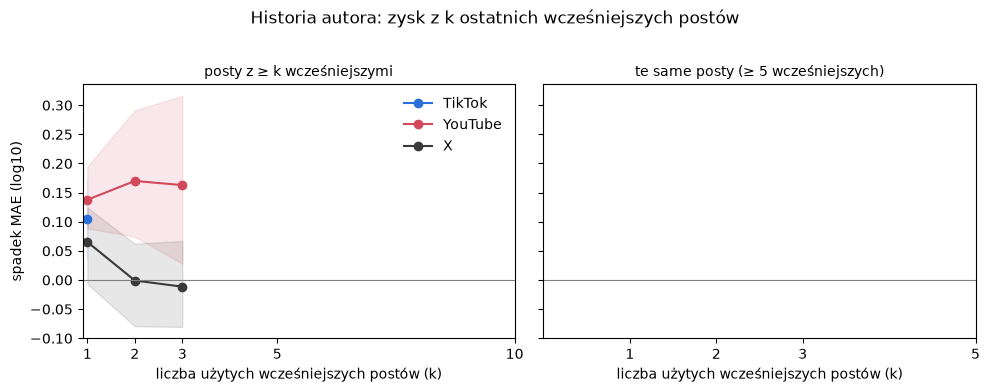

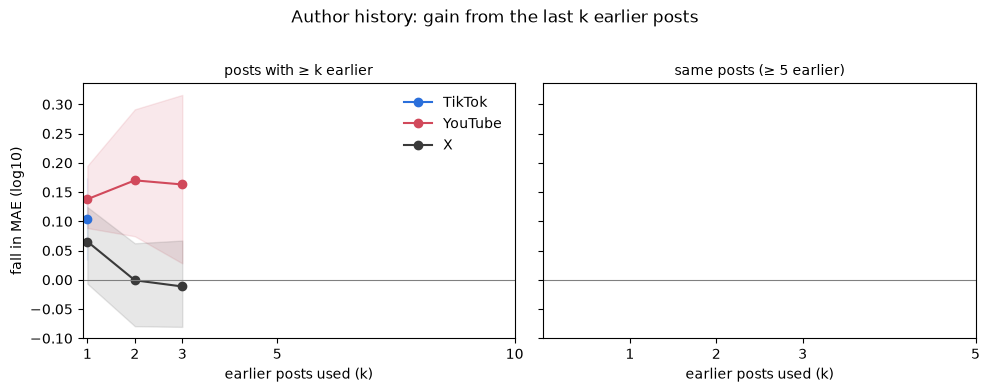

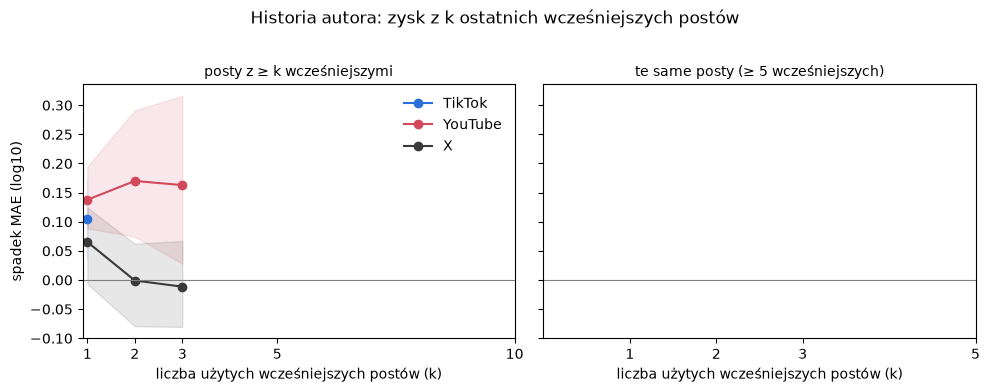

In [6]:
an.plot_curve(C77, ROOT / "figures" / "history_curve_en.png", "en"); an.plot_curve(C77, ROOT / "figures" / "history_curve_pl.png", "pl")

## E78 · Author level without views
Columns from the author's other posts in the sample (reactions only).

In [7]:
X78 = an.author_proxy(raw_all, raw); P78 = an.with_columns(f, meta, X78, "+ author proxy (other posts, no views)"); S78 = H.summarise(P78); display(S78.round(3))
G78 = pd.DataFrame([{"platform": p, "model": k, **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(P78, p, "final model", k)))} for p in an.PLATS for k in ['+ author proxy (other posts, no views)']]); display(G78.round(3))
has = X78.other_posts.reindex(P78.idx).values >= 1; P78h = P78[has]; G78h = pd.DataFrame([{"platform": p, "model": k, **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(P78h, p, "final model", k)))} for p in an.PLATS for k in ['+ author proxy (other posts, no views)']])
G78h["posts"] = [int(((P78h.platform == p) & (P78h.model == "final model")).sum()) for p in an.PLATS]; G78h.round(3)

,platform,model,posts,MAE,CI low,CI high,bias
0,tiktok,final model,2491,0.273,0.263,0.285,-0.020
1,tiktok,"+ author proxy (other posts, no views)",2491,0.275,0.264,0.288,-0.021
2,youtube,final model,2441,0.456,0.434,0.480,-0.039
3,youtube,"+ author proxy (other posts, no views)",2441,0.455,0.432,0.482,-0.044
4,twitter,final model,1803,0.466,0.446,0.489,-0.039
5,twitter,"+ author proxy (other posts, no views)",1803,0.467,0.445,0.490,-0.038


,platform,model,gain,CI low,CI high
0,tiktok,"+ author proxy (other posts, no views)",-0.002,-0.005,0.001
1,youtube,"+ author proxy (other posts, no views)",0.000,-0.005,0.006
2,twitter,"+ author proxy (other posts, no views)",-0.000,-0.006,0.005


,platform,model,gain,CI low,CI high,posts
0,tiktok,"+ author proxy (other posts, no views)",-0.047,-0.086,-0.007,142
1,youtube,"+ author proxy (other posts, no views)",0.016,-0.000,0.034,662
2,twitter,"+ author proxy (other posts, no views)",-0.002,-0.036,0.030,245


In [8]:
# does the proxy track the author level? Spearman of other-post likes per follower with r, on posts whose author has other posts
pd.DataFrame([{"platform": p, **{c: spearmanr_ for c, spearmanr_ in [(c, float(pd.Series(X78[c][(meta.platform == p).values & (X78.other_posts >= 1).values]).corr(d.r[(meta.platform == p).values & (X78.other_posts >= 1).values], method="spearman"))) for c in ["other_mean_log_likes", "other_likes_per_follower", "other_zero_share"]]}} for p in an.PLATS]).round(3)

,platform,other_mean_log_likes,other_likes_per_follower,other_zero_share
0,tiktok,0.181,0.014,-0.045
1,youtube,0.078,-0.004,-0.057
2,twitter,0.135,-0.046,-0.148


## E79 · Live forecast plus author history
E40 pairs (first check → later check), forecast by CatBoost on the first check; then the author's earlier posts.

In [9]:
dl = an.live_frame(ROOT, raw_all); hl = am.history_features(dl); print(hl.hn.notna().groupby(dl.platform).sum().to_dict())
hnow = h.set_axis(raw.mention_id.astype(str).tolist())
P79 = an.live_compare(dl, hl, hnow); S79 = H.summarise(P79); display(S79.round(3))
G79 = pd.DataFrame([{"platform": p, "model": k, **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(P79, p, "live forecast (E40)", k)))} for p in an.PLATS for k in ['+ author history (forecast residuals)', '+ author history (now-cast residuals)']]); G79.round(3)

{'tiktok': 7, 'twitter': 21, 'youtube': 31}


,platform,model,posts,MAE,CI low,CI high,bias
0,youtube,live forecast (E40),31,0.103,0.057,0.159,0.016
1,youtube,+ author history (forecast residuals),31,0.098,0.052,0.160,0.001
2,youtube,+ author history (now-cast residuals),31,0.162,0.105,0.230,0.006


,platform,model,gain,CI low,CI high
0,tiktok,+ author history (forecast residuals),NaN,NaN,NaN
1,tiktok,+ author history (now-cast residuals),NaN,NaN,NaN
2,youtube,+ author history (forecast residuals),0.005,-0.036,0.041
3,youtube,+ author history (now-cast residuals),-0.060,-0.101,-0.019
4,twitter,+ author history (forecast residuals),NaN,NaN,NaN
5,twitter,+ author history (now-cast residuals),NaN,NaN,NaN


## E80 · Intervals for brand totals

In [10]:
I80 = an.brand_intervals(meta, pred); I80.round(3)

,platform,method,nominal,brands,coverage,median half-width (×),size
0,tiktok,A: brand-level quantiles,0.8,238,0.790,2.191,NaN
1,tiktok,A: by brand size,0.8,238,0.777,2.223,NaN
2,tiktok,B: independent post residuals,0.8,238,0.752,2.015,NaN
3,tiktok,A: brand-level quantiles,0.9,238,0.882,2.893,NaN
4,tiktok,A: by brand size,0.9,238,0.878,2.964,NaN
5,tiktok,B: independent post residuals,0.9,238,0.861,2.627,NaN
6,tiktok,spread of brand log ratio by size,NaN,127,NaN,2.905,10-29
7,tiktok,spread of brand log ratio by size,NaN,4,NaN,1.536,30+
8,tiktok,spread of brand log ratio by size,NaN,107,NaN,2.738,5-9
9,youtube,A: brand-level quantiles,0.8,213,0.798,2.997,NaN


## Takeaways
See `docs/en/experiments.md` (E76-E80). Numbers: `data/processed/author_next_numbers.json`.

In [11]:
json.dump({"error_breakdown": B76.to_dict("records"), "top_authors": A76.to_dict("records"), "traits_models": S76.to_dict("records"), "traits_gain": G76.to_dict("records"),
           "history_curve": C77.to_dict("records"), "proxy_models": S78.to_dict("records"), "proxy_gain": G78.to_dict("records"), "proxy_gain_with_other_posts": G78h.to_dict("records"),
           "live_models": S79.to_dict("records"), "live_gains": G79.to_dict("records"), "brand_intervals": I80.to_dict("records")},
          open(ROOT / "data" / "processed" / "author_next_numbers.json", "w"), indent=1, default=float)